In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/adrikapradhan/vllm-project-output/vllm_vs_hf_benchmark.png
/kaggle/input/datasets/adrikapradhan/vllm-project-output/final_vllm_vs_hf_benchmark.csv
/kaggle/input/datasets/adrikapradhan/vllm-project-output/__huggingface_repos__.json
/kaggle/input/datasets/adrikapradhan/vllm-project-output/vllm_vs_hf_final_comparison.png
/kaggle/input/datasets/adrikapradhan/vllm-project-output/run_metadata.csv
/kaggle/input/datasets/adrikapradhan/vllm-project-output/benchmark_results.csv


In [2]:
# Install required libraries for PEFT, LoRA fine-tuning, and evaluation metrics
!pip install -q peft transformers trl bitsandbytes accelerate datasets pandas matplotlib seaborn
!pip install -q -U transformers torchao
print("[CHECKPOINT 1] Environment dependencies installed successfully.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 945.8/945.8 kB 13.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 49.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 91.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 63.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 23.8 MB/s eta 0:00:00
[CHECKPOINT 1] Environment dependencies installed successfully.


In [3]:
# Use a pipeline as a high-level helper
from transformers import pipeline

pipe = pipeline("text-generation", model="Qwen/Qwen2.5-1.5B-Instruct")
messages = [
    {"role": "user", "content": "Who are you?"},
]
pipe(messages)

Failed to load /usr/local/lib/python3.13/dist-packages/torchao/_C_cutlass_90a.abi3.so: Could not load this library: /usr/local/lib/python3.13/dist-packages/torchao/_C_cutlass_90a.abi3.so
Failed to load /usr/local/lib/python3.13/dist-packages/torchao/_C_mxfp8.cpython-310-x86_64-linux-gnu.so: Could not load this library: /usr/local/lib/python3.13/dist-packages/torchao/_C_mxfp8.cpython-310-x86_64-linux-gnu.so


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

...

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer Qwen2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


[{'generated_text': [{'role': 'user', 'content': 'Who are you?'},
   {'role': 'assistant',
    'content': 'I am Qwen, an AI language model developed by Alibaba Cloud. I can help answer questions and engage in conversation on various topics. How may I assist you today?'}]}]

In [4]:
# pip install -U transformers accelerate
# Load model directly
from transformers import AutoTokenizer, AutoModelForCausalLM

tokenizer = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-1.5B-Instruct")
model = AutoModelForCausalLM.from_pretrained("Qwen/Qwen2.5-1.5B-Instruct", device_map="auto")
messages = [
    {"role": "user", "content": "Who are you?"},
]
inputs = tokenizer.apply_chat_template(
	messages,
	add_generation_prompt=True,
	tokenize=True,
	return_dict=True,
	return_tensors="pt",
).to(model.device)

outputs = model.generate(**inputs, max_new_tokens=256)
print(tokenizer.decode(outputs[0][inputs["input_ids"].shape[-1]:]))

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

I am Qwen, an AI language model developed by Alibaba Cloud. I can assist with various tasks such as answering questions, generating text, and providing information on different topics. Please feel free to ask me anything!<|im_end|>


In [5]:
import torch
from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"

# 1. Load Tokenizer & Model Configuration
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
print(f"[CHECKPOINT 2.1] Tokenizer loaded successfully. Pad token: {tokenizer.pad_token}")



[CHECKPOINT 2.1] Tokenizer loaded successfully. Pad token: <|endoftext|>


In [6]:
# 2. Sample Instruction-Response Dataset
train_data = [
    {
        "instruction": "Convert the following casual message into a formal academic sentence.",
        "input": "Hey, vLLM makes LLM running super fast because it fixes GPU memory waste.",
        "output": "vLLM significantly enhances Large Language Model serving throughput by eliminating key-value cache memory fragmentation via paged virtual memory allocation."
    },
    {
        "instruction": "Convert the following casual message into a formal academic sentence.",
        "input": "LoRA is cool because you don't need to retrain all model weights, just small matrices.",
        "output": "Low-Rank Adaptation (LoRA) reduces parameter-efficient fine-tuning overhead by freezing pre-trained weights and optimizing low-rank decomposition matrices."
    },
    {
        "instruction": "Convert the following casual message into a formal academic sentence.",
        "input": "If you don't clear GPU VRAM in PyTorch, your code crashes with out of memory errors.",
        "output": "Failure to explicitly release unreferenced GPU tensors and clear the CUDA allocator cache inevitably leads to runtime Out-Of-Memory exceptions."
    },
    {
        "instruction": "Convert the following casual message into a formal academic sentence.",
        "input": "PagedAttention works just like OS virtual memory paging.",
        "output": "PagedAttention adapts the classical operating system principle of virtual memory paging to store attention Key-Value states in non-contiguous physical memory blocks."
    }
] * 25  # Simulated dataset expansion for quick Kaggle training execution

dataset = Dataset.from_list(train_data)

def format_prompts(example):
    text = f"<|im_start|>user\n{example['instruction']}\nInput: {example['input']}<|im_end|>\n<|im_start|>assistant\n{example['output']}<|im_end|>"
    return {"text": text}

formatted_dataset = dataset.map(format_prompts)
print(f"[CHECKPOINT 2.2] Dataset formatted successfully. Total training samples: {len(formatted_dataset)}")
print("Sample prompt:\n", formatted_dataset["text"][0])

Map:   0%|          | 0/100 [00:00<?, ? examples/s]

[CHECKPOINT 2.2] Dataset formatted successfully. Total training samples: 100
Sample prompt:
 <|im_start|>user
Convert the following casual message into a formal academic sentence.
Input: Hey, vLLM makes LLM running super fast because it fixes GPU memory waste.<|im_end|>
<|im_start|>assistant
vLLM significantly enhances Large Language Model serving throughput by eliminating key-value cache memory fragmentation via paged virtual memory allocation.<|im_end|>


In [7]:
import os
import gc
import time
import pandas as pd
from peft import LoraConfig, get_peft_model, TaskType
from trl import SFTConfig, SFTTrainer

RANKS = [4, 8, 16]
ablation_results = []
print(f"[CHECKPOINT 3.1] Starting rank ablation study for ranks: {RANKS}")

for r in RANKS:
    print(f"\n==========================================")
    print(f"   Starting LoRA Fine-Tuning for Rank r={r}")
    print(f"==========================================")

    # 1. Load Fresh Base Model
    model = AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        torch_dtype=torch.float16,
        device_map="auto"
    )
    print(f"[CHECKPOINT 3.2] Base model loaded successfully for r={r}.")

    # 2. Configure LoRA Parameters
    peft_config = LoraConfig(
        task_type=TaskType.CAUSAL_LM,
        r=r,
        lora_alpha=16,
        target_modules=["q_proj", "v_proj"],
        lora_dropout=0.05,
        bias="none"
    )

    peft_model = get_peft_model(model, peft_config)

    trainable_params, all_param = peft_model.get_nb_trainable_parameters()
    trainable_pct = 100 * trainable_params / all_param
    print(f"Trainable Parameters: {trainable_params:,} / {all_param:,} ({trainable_pct:.4f}%)")

    # 3. Define SFTConfig & Trainer Arguments
    output_dir = f"./lora_adapter_r{r}"
    
    sft_config = SFTConfig(
        output_dir=output_dir,
        per_device_train_batch_size=2,
        gradient_accumulation_steps=2,
        learning_rate=2e-4,
        num_train_epochs=3,
        logging_steps=5,
        fp16=True,
        save_strategy="no",
        report_to="none",
        dataset_text_field="text",
        max_length=256  # Updated from max_seq_length to match current SFTConfig specs
    )

    trainer = SFTTrainer(
        model=peft_model,
        train_dataset=formatted_dataset,
        args=sft_config
    )
    print(f"[CHECKPOINT 3.3] SFTTrainer initialized successfully for r={r}. Beginning training loop...")

    # 4. Measure Training Metrics & VRAM Consumption
    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()
    start_time = time.perf_counter()

    train_result = trainer.train()

    torch.cuda.synchronize()
    elapsed_time = time.perf_counter() - start_time
    peak_vram_gb = torch.cuda.max_memory_allocated() / (1024 ** 3)
    print(f"[CHECKPOINT 3.4] Training finished for r={r} in {elapsed_time:.2f}s. Peak VRAM: {peak_vram_gb:.2f} GB")

    # 5. Save Adapter Checkpoint
    peft_model.save_pretrained(output_dir)
    print(f"[CHECKPOINT 3.5] Saved LoRA rank r={r} adapter to '{output_dir}' successfully.")

    ablation_results.append({
        "Rank (r)": r,
        "Trainable Params": trainable_params,
        "Trainable (%)": round(trainable_pct, 4),
        "Training Time (s)": round(elapsed_time, 2),
        "Peak VRAM (GB)": round(peak_vram_gb, 2),
        "Final Training Loss": round(train_result.training_loss, 4)
    })

    # Clear memory cleanly between runs
    del peft_model, model, trainer
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.synchronize()

# Save Ablation Summary DataFrame
df_ablation = pd.DataFrame(ablation_results)
df_ablation.to_csv("lora_rank_ablation.csv", index=False)
print("\n[CHECKPOINT 3.6] All rank runs completed. Ablation summary saved to 'lora_rank_ablation.csv'.")
print(df_ablation.to_string(index=False))

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


[CHECKPOINT 3.1] Starting rank ablation study for ranks: [4, 8, 16]

   Starting LoRA Fine-Tuning for Rank r=4


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

[CHECKPOINT 3.2] Base model loaded successfully for r=4.
Trainable Parameters: 544,768 / 1,544,259,072 (0.0353%)


Adding EOS to train dataset:   0%|          | 0/100 [00:00<?, ? examples/s]

...

Truncating train dataset:   0%|          | 0/100 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/100 [00:00<?, ? examples/s]

[CHECKPOINT 3.3] SFTTrainer initialized successfully for r=16. Beginning training loop...


Step,Training Loss
5,4.699932
10,3.954572
15,3.627248
20,3.330938
25,2.991574
30,2.636501
35,2.442244
40,2.186470
45,2.021478
50,1.720534


[CHECKPOINT 3.4] Training finished for r=16 in 48.55s. Peak VRAM: 4.77 GB
[CHECKPOINT 3.5] Saved LoRA rank r=16 adapter to './lora_adapter_r16' successfully.

[CHECKPOINT 3.6] All rank runs completed. Ablation summary saved to 'lora_rank_ablation.csv'.
 Rank (r)  Trainable Params  Trainable (%)  Training Time (s)  Peak VRAM (GB)  Final Training Loss
        4            544768         0.0353              55.50            6.55               2.4458
        8           1089536         0.0705              47.83            4.76               2.4438
       16           2179072         0.1410              48.55            4.77               2.4248


In [8]:
from peft import PeftModel

test_prompt = "<|im_start|>user\nConvert the following casual message into a formal academic sentence.\nInput: PagedAttention stops GPU memory from being wasted when generating text.<|im_end|>\n<|im_start|>assistant\n"

# 1. Base Model Generation (No Adapter)
base_model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.float16,
    device_map="auto"
)
inputs = tokenizer(test_prompt, return_tensors="pt").to("cuda")

with torch.inference_mode():
    base_out = base_model.generate(**inputs, max_new_tokens=64, do_sample=False)
# Fixed: use shape[1] to get the integer sequence length
base_text = tokenizer.decode(base_out[0][inputs.input_ids.shape[1]:], skip_special_tokens=True)

# 2. LoRA Adapter Generation (r=16)
lora_model = PeftModel.from_pretrained(base_model, "./lora_adapter_r16")
with torch.inference_mode():
    lora_out = lora_model.generate(**inputs, max_new_tokens=64, do_sample=False)
# Fixed: use shape[1] to get the integer sequence length
lora_text = tokenizer.decode(lora_out[0][inputs.input_ids.shape[1]:], skip_special_tokens=True)

print("[CHECKPOINT 4] Qualitative evaluation generated successfully.")
print("=== Qualitative Completion Comparison ===")
print("Input Casual Prompt: 'PagedAttention stops GPU memory from being wasted when generating text.'")
print("\n[Base Model Output]:\n", base_text)
print("\n[LoRA Fine-Tuned Output (r=16)]:\n", lora_text)

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

[CHECKPOINT 4] Qualitative evaluation generated successfully.
=== Qualitative Completion Comparison ===
Input Casual Prompt: 'PagedAttention stops GPU memory from being wasted when generating text.'

[Base Model Output]:
 The software, Page Attention, effectively prevents GPU memory wastage during the generation of textual content.

[LoRA Fine-Tuned Output (r=16)]:
 PagedAttention effectively prevents GPU memory wastage during text generation by ensuring that only necessary data is retained in VRAM.


/tmp/ipykernel_23/3622359293.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_plot, x="Rank (r)", y="Trainable Params", palette="Blues_d", ax=axes[0])


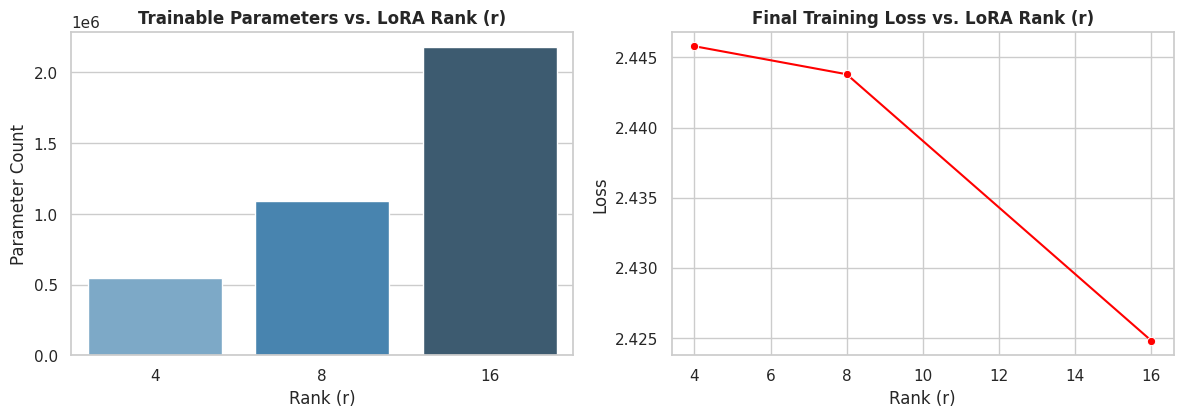

[CHECKPOINT 5] Visualization plots successfully rendered and saved to 'lora_rank_ablation.png'.


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

df_plot = pd.read_csv("lora_rank_ablation.csv")
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Plot 1: Trainable Parameters vs. Rank
sns.barplot(data=df_plot, x="Rank (r)", y="Trainable Params", palette="Blues_d", ax=axes[0])
axes[0].set_title("Trainable Parameters vs. LoRA Rank (r)", fontweight="bold")
axes[0].set_ylabel("Parameter Count")

# Plot 2: Peak VRAM & Training Loss
sns.lineplot(data=df_plot, x="Rank (r)", y="Final Training Loss", marker="o", color="red", ax=axes[1])
axes[1].set_title("Final Training Loss vs. LoRA Rank (r)", fontweight="bold")
axes[1].set_ylabel("Loss")

plt.tight_layout()
plt.savefig("lora_rank_ablation.png", dpi=300)
plt.show()
print("[CHECKPOINT 5] Visualization plots successfully rendered and saved to 'lora_rank_ablation.png'.")

In [10]:
# Clear active model variables and release CUDA memory cache completely
import gc
import torch

try:
    del base_model
    del lora_model
    del inputs
    del base_out
    del lora_out
except NameError:
    pass

gc.collect()
torch.cuda.empty_cache()
torch.cuda.synchronize()

# Print current memory footprint stats
allocated_vram = torch.cuda.memory_allocated() / (1024 ** 3)
reserved_vram = torch.cuda.memory_reserved() / (1024 ** 3)
print(f"[CHECKPOINT 6] GPU Memory Cleanup Complete.")
print(f"Current Allocated VRAM: {allocated_vram:.2f} GB")
print(f"Current Reserved VRAM: {reserved_vram:.2f} GB")

[CHECKPOINT 6] GPU Memory Cleanup Complete.
Current Allocated VRAM: 2.89 GB
Current Reserved VRAM: 3.10 GB
